In [1]:
%pip install -q openpyxl requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import requests

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

In [3]:
URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/flight-fare.zip"

if not os.path.exists("flight-fare.zip"):
    r = requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    r.raise_for_status()                      # stops here with a clear error if the download fails
    with open("flight-fare.zip", "wb") as f:
        f.write(r.content)

with zipfile.ZipFile("flight-fare.zip") as z:
    z.extractall("flight_data")

# show every file we got
for f in glob.glob("flight_data/**/*", recursive=True):
    print(f)

flight_data\Flight_Fare.xlsx


In [4]:
for f in glob.glob("flight_data/**/*", recursive=True):
    print(f, "|", "folder" if os.path.isdir(f) else f"{os.path.getsize(f)/1024:.0f} KB")

flight_data\Flight_Fare.xlsx | 518 KB


In [5]:
files = [
    f for f in glob.glob("flight_data/**/*", recursive=True)
    if f.lower().endswith((".xlsx", ".xls", ".csv")) and "__MACOSX" not in f
]
print("Candidate data files:", files)

def read_any(path):
    return pd.read_csv(path) if path.lower().endswith(".csv") else pd.read_excel(path)

# pick the file that has the 'Price' column (that's the labelled data we need)
df = None
for f in files:
    tmp = read_any(f)
    print(f, "->", tmp.shape, "| has Price:", "Price" in tmp.columns)
    if "Price" in tmp.columns and df is None:
        df = tmp
        train_path = f

print("\nUsing:", train_path)
print("Shape:", df.shape)
df.head()

Candidate data files: ['flight_data\\Flight_Fare.xlsx']
flight_data\Flight_Fare.xlsx -> (10683, 11) | has Price: True

Using: flight_data\Flight_Fare.xlsx
Shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [6]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB

Missing values:
 Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

Duplicate rows: 220


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Airline,10683,12,Jet Airways,3849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date_of_Journey,10683,44,18/05/2019,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,10683,5,Delhi,4537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,10683,6,Cochin,4537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route,10682,128,DEL → BOM → COK,2376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dep_Time,10683,222,18:55,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arrival_Time,10683,1343,19:00,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration,10683,368,2h 50m,550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Stops,10682,5,1 stop,5625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Additional_Info,10683,10,No info,8345,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Before:", df.shape)

# 1) drop the rows with missing values (only a tiny number, so safe to remove)
df = df.dropna()

# 2) drop exact duplicate rows
df = df.drop_duplicates()

# 3) reset the index so it runs 0,1,2,... again
df = df.reset_index(drop=True)

print("After:", df.shape)
print("Missing now:", df.isnull().sum().sum())

Before: (10683, 11)
After: (10462, 11)
Missing now: 0


In [8]:
for col in ["Airline", "Source", "Destination", "Total_Stops", "Additional_Info"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

--- Airline ---
Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64 

--- Source ---
Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64 

--- Destination ---
Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64 

--- Total_Stops ---
Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int6

In [9]:
data = df.copy()

# --- Journey date: "24/03/2019" -> day, month, weekday ---
jd = pd.to_datetime(data["Date_of_Journey"], format="%d/%m/%Y")
data["Journey_Day"] = jd.dt.day
data["Journey_Month"] = jd.dt.month
data["Journey_Weekday"] = jd.dt.dayofweek      # 0 = Monday ... 6 = Sunday

# --- Departure time: "22:20" -> hour, minute ---
dep = pd.to_datetime(data["Dep_Time"], format="%H:%M")
data["Dep_Hour"] = dep.dt.hour
data["Dep_Min"] = dep.dt.minute

# --- Arrival time: sometimes "01:10 22 Mar" (next day), so grab only the HH:MM part ---
arr_time = data["Arrival_Time"].str.extract(r"(\d{1,2}:\d{2})")[0]
arr = pd.to_datetime(arr_time, format="%H:%M")
data["Arrival_Hour"] = arr.dt.hour
data["Arrival_Min"] = arr.dt.minute

data[["Journey_Day", "Journey_Month", "Journey_Weekday",
      "Dep_Hour", "Dep_Min", "Arrival_Hour", "Arrival_Min"]].head()

,Journey_Day,Journey_Month,Journey_Weekday,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min
0,24,3,6,22,20,1,10
1,1,5,2,5,50,13,15
2,9,6,6,9,25,4,25
3,12,5,6,18,5,23,30
4,1,3,4,16,50,21,35


In [10]:
def duration_to_minutes(s):
    s = str(s)
    hours = pd.Series([s]).str.extract(r"(\d+)\s*h")[0].astype(float).fillna(0).iloc[0]
    mins  = pd.Series([s]).str.extract(r"(\d+)\s*m")[0].astype(float).fillna(0).iloc[0]
    return int(hours * 60 + mins)

data["Duration_Mins"] = data["Duration"].apply(duration_to_minutes)

data[["Duration", "Duration_Mins"]].head(8)

,Duration,Duration_Mins
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285
5,2h 25m,145
6,15h 30m,930
7,21h 5m,1265


In [11]:
# --- Total_Stops: text -> number ---
print(data["Total_Stops"].unique())

stops_map = {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}
data["Total_Stops"] = data["Total_Stops"].map(stops_map)

# --- Additional_Info: fix the same label written two ways ---
data["Additional_Info"] = data["Additional_Info"].replace({"No Info": "No info"})

print("\nMissing after mapping:", data["Total_Stops"].isnull().sum())

<ArrowStringArray>
['non-stop', '2 stops', '1 stop', '3 stops', '4 stops']
Length: 5, dtype: str

Missing after mapping: 0


In [12]:
data = data.drop(columns=["Date_of_Journey", "Dep_Time", "Arrival_Time", "Duration"])

print(data.shape)
data.dtypes

(10462, 15)


Airline              str
Source               str
Destination          str
Route                str
Total_Stops        int64
Additional_Info      str
Price              int64
Journey_Day        int32
Journey_Month      int32
Journey_Weekday    int32
Dep_Hour           int32
Dep_Min            int32
Arrival_Hour       int32
Arrival_Min        int32
Duration_Mins      int64
dtype: object

count    10462.000000
mean      9026.790289
std       4624.849541
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12344.750000
max      79512.000000
Name: Price, dtype: float64
Skewness: 1.86


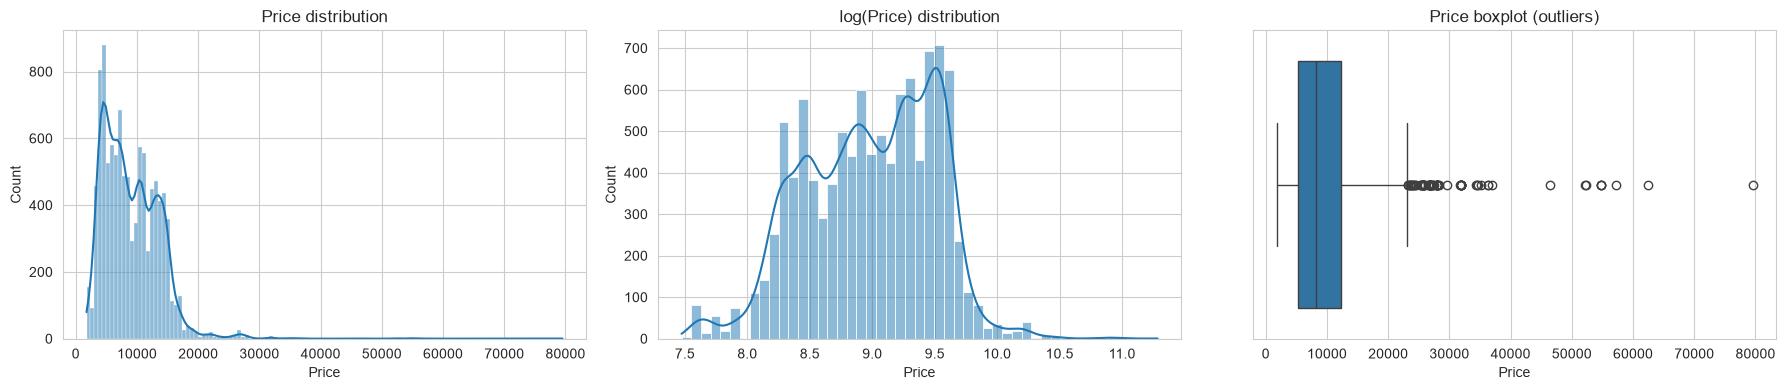

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

print(data["Price"].describe())
print("Skewness:", round(data["Price"].skew(), 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(data["Price"], kde=True, ax=ax[0]).set_title("Price distribution")
sns.histplot(np.log1p(data["Price"]), kde=True, ax=ax[1]).set_title("log(Price) distribution")
sns.boxplot(x=data["Price"], ax=ax[2]).set_title("Price boxplot (outliers)")
plt.tight_layout(); plt.show()

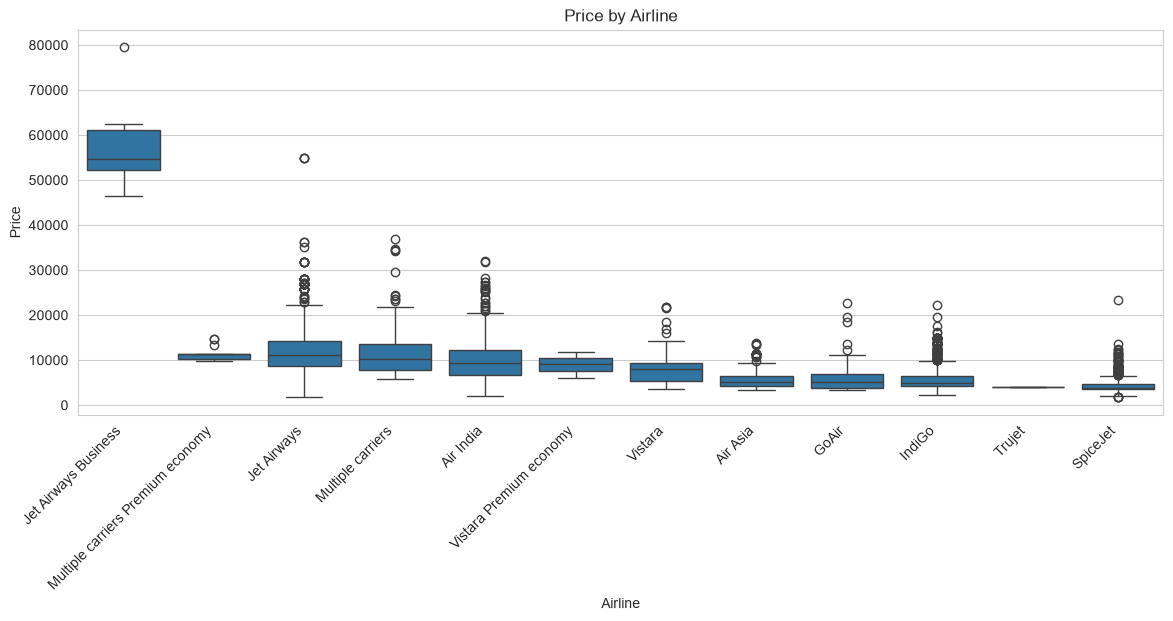

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64


In [14]:
order = data.groupby("Airline")["Price"].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 5))
sns.boxplot(data=data, x="Airline", y="Price", order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Price by Airline")
plt.show()

print(data["Airline"].value_counts())

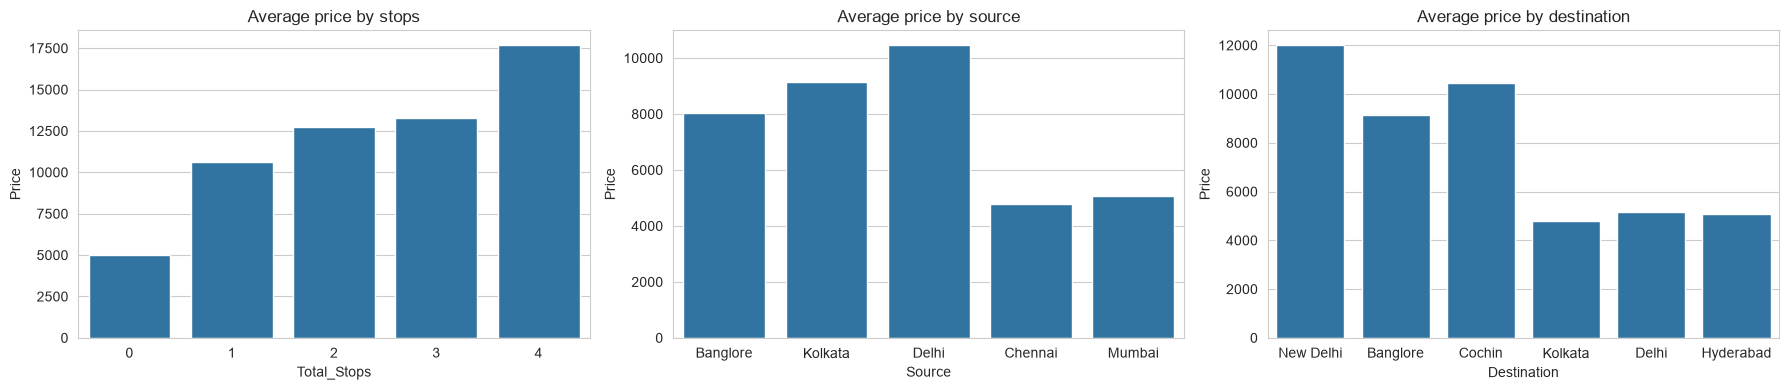

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

sns.barplot(data=data, x="Total_Stops", y="Price", ax=ax[0], estimator="mean", errorbar=None)
ax[0].set_title("Average price by stops")

sns.barplot(data=data, x="Source", y="Price", ax=ax[1], estimator="mean", errorbar=None)
ax[1].set_title("Average price by source")

sns.barplot(data=data, x="Destination", y="Price", ax=ax[2], estimator="mean", errorbar=None)
ax[2].set_title("Average price by destination")

plt.tight_layout(); plt.show()

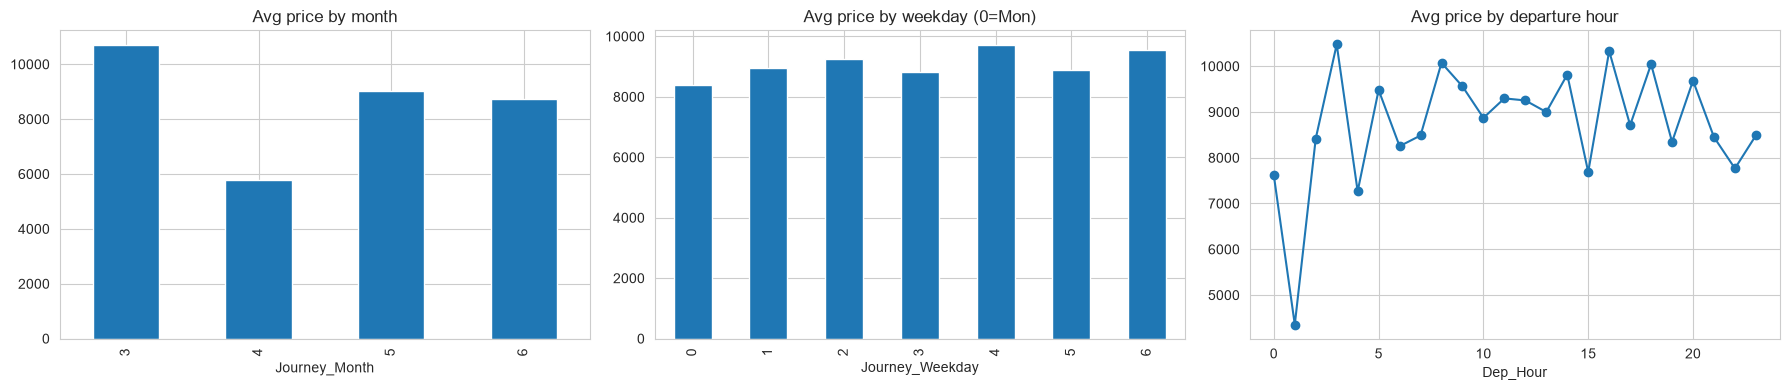

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

data.groupby("Journey_Month")["Price"].mean().plot(kind="bar", ax=ax[0], title="Avg price by month")
data.groupby("Journey_Weekday")["Price"].mean().plot(kind="bar", ax=ax[1], title="Avg price by weekday (0=Mon)")
data.groupby("Dep_Hour")["Price"].mean().plot(kind="line", marker="o", ax=ax[2], title="Avg price by departure hour")

plt.tight_layout(); plt.show()

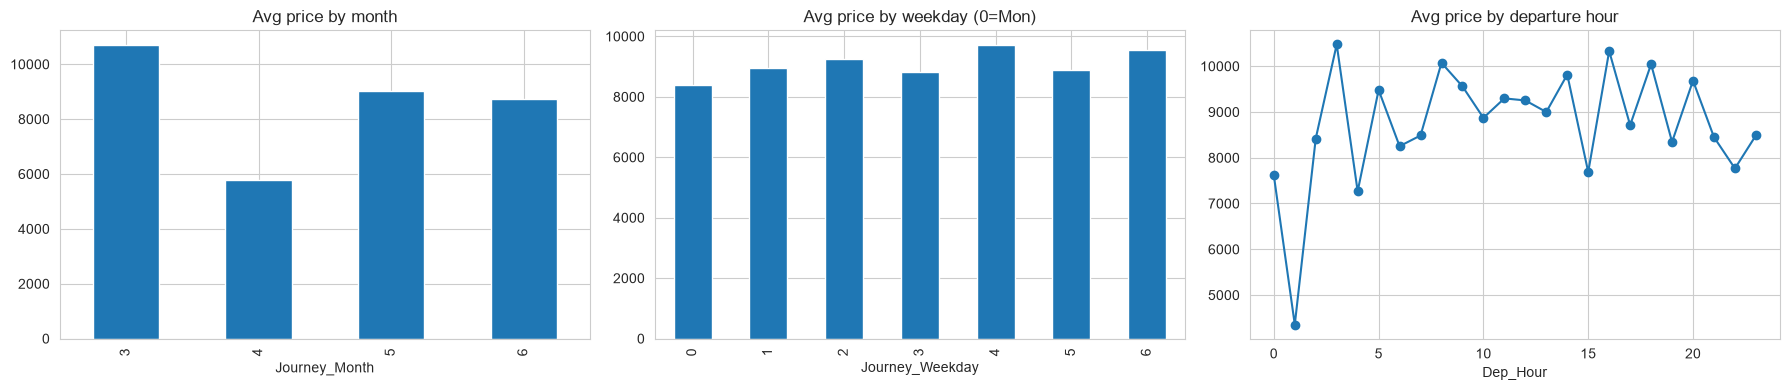

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

data.groupby("Journey_Month")["Price"].mean().plot(kind="bar", ax=ax[0], title="Avg price by month")
data.groupby("Journey_Weekday")["Price"].mean().plot(kind="bar", ax=ax[1], title="Avg price by weekday (0=Mon)")
data.groupby("Dep_Hour")["Price"].mean().plot(kind="line", marker="o", ax=ax[2], title="Avg price by departure hour")

plt.tight_layout(); plt.show()

Additional_Info
No info                         8185
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

Unique routes: 128


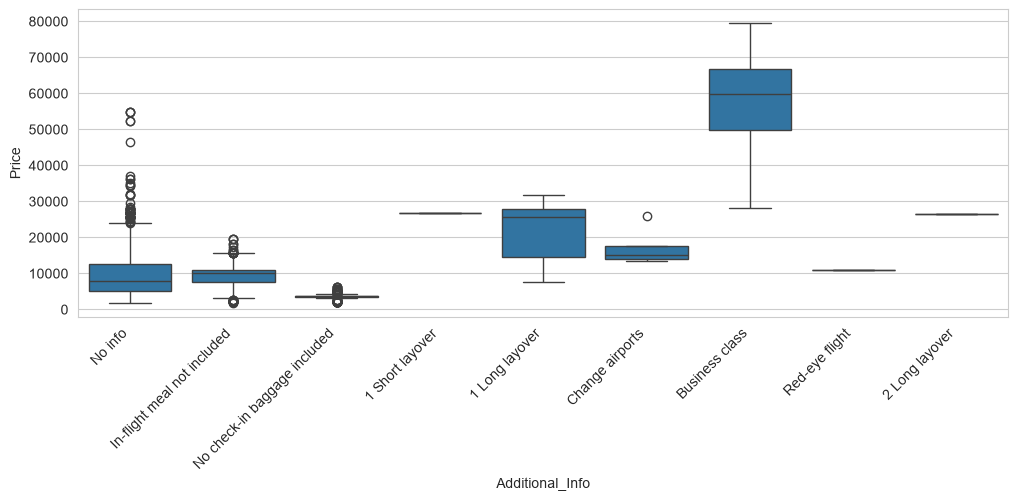

In [18]:
print(data["Additional_Info"].value_counts())
print("\nUnique routes:", data["Route"].nunique())

plt.figure(figsize=(12, 4))
sns.boxplot(data=data, x="Additional_Info", y="Price")
plt.xticks(rotation=45, ha="right")
plt.show()

In [19]:
# Delhi and New Delhi are the same city (airport renamed), so merge them if both exist
print(data["Destination"].unique())
data["Destination"] = data["Destination"].replace({"New Delhi": "Delhi"})

# Route is redundant: it's already covered by Source, Destination and Total_Stops
model_df = data.drop(columns=["Route"])

print(model_df.shape)
model_df.head()

<ArrowStringArray>
['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad']
Length: 6, dtype: str
(10462, 14)


,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Weekday,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Mins
0,IndiGo,Banglore,Delhi,0,No info,3897,24,3,6,22,20,1,10,170
1,Air India,Kolkata,Banglore,2,No info,7662,1,5,2,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,2,No info,13882,9,6,6,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,1,No info,6218,12,5,6,18,5,23,30,325
4,IndiGo,Banglore,Delhi,1,No info,13302,1,3,4,16,50,21,35,285


In [20]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["Price"])
y = model_df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (8369, 13) | Test: (2093, 13)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["Airline", "Source", "Destination", "Additional_Info"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['Airline', 'Source', 'Destination', 'Additional_Info']
Numeric: ['Total_Stops', 'Journey_Day', 'Journey_Month', 'Journey_Weekday', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Mins']


In [22]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

In [23]:
%pip install -q xgboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# linear models need scaled numbers, tree models don't
prep_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

models = {
    "Linear Regression": Pipeline([("prep", prep_scaled), ("model", LinearRegression())]),
    "Ridge":             Pipeline([("prep", prep_scaled), ("model", Ridge(alpha=1.0))]),
    "Decision Tree":     Pipeline([("prep", preprocessor), ("model", DecisionTreeRegressor(random_state=42))]),
    "Random Forest":     Pipeline([("prep", preprocessor), ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("prep", preprocessor), ("model", GradientBoostingRegressor(random_state=42))]),
    "XGBoost":           Pipeline([("prep", preprocessor), ("model", XGBRegressor(n_estimators=300, learning_rate=0.1, random_state=42, n_jobs=-1))]),
}

In [25]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score
import time

results = []

for name, pipe in models.items():
    start = time.time()
    pipe.fit(X_train, y_train_log)
    secs = time.time() - start

    # predictions are in log scale, so convert back to rupees
    pred_train = np.expm1(pipe.predict(X_train))
    pred_test  = np.expm1(pipe.predict(X_test))

    cv = cross_val_score(pipe, X_train, y_train_log, cv=5, scoring="r2", n_jobs=-1)

    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "CV R2 (log, 5-fold)": cv.mean(),
        "MAE (Rs)": mean_absolute_error(y_test, pred_test),
        "RMSE (Rs)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Fit time (s)": secs,
    })
    print(f"done: {name}")

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
results_df.round(3)

done: Linear Regression
done: Ridge
done: Decision Tree
done: Random Forest
done: Gradient Boosting
done: XGBoost


,Model,Train R2,Test R2,"CV R2 (log, 5-fold)",MAE (Rs),RMSE (Rs),Fit time (s)
0,XGBoost,0.967,0.907,0.944,702.937,1395.993,2.180
1,Random Forest,0.973,0.892,0.934,649.483,1502.045,3.021
2,Decision Tree,0.996,0.821,0.886,794.379,1933.394,0.240
3,Gradient Boosting,0.824,0.804,0.870,1232.740,2022.189,3.433
4,Ridge,0.660,0.631,0.759,1752.959,2774.043,0.138
5,Linear Regression,0.662,0.631,0.759,1752.295,2774.811,0.199


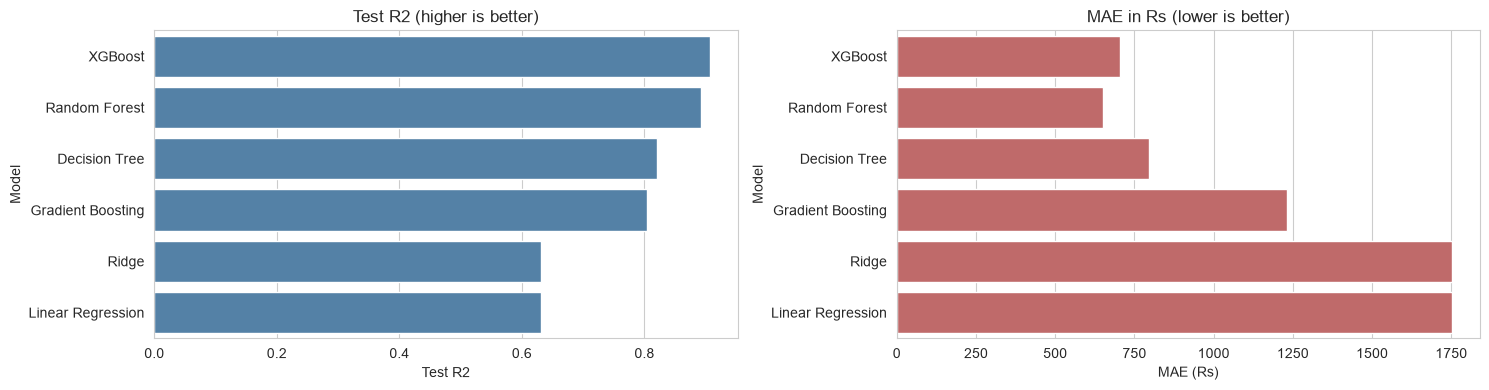

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sns.barplot(data=results_df, x="Test R2", y="Model", ax=ax[0], color="steelblue")
ax[0].set_title("Test R2 (higher is better)")

sns.barplot(data=results_df, x="MAE (Rs)", y="Model", ax=ax[1], color="indianred")
ax[1].set_title("MAE in Rs (lower is better)")

plt.tight_layout(); plt.show()

In [27]:
from sklearn.model_selection import RandomizedSearchCV

search_spaces = {
    "Random Forest": (
        Pipeline([("prep", preprocessor),
                  ("model", RandomForestRegressor(random_state=42, n_jobs=-1))]),
        {
            "model__n_estimators": [200, 300, 500],
            "model__max_depth": [None, 15, 25, 35],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.5, 1.0],
        },
    ),
    "XGBoost": (
        Pipeline([("prep", preprocessor),
                  ("model", XGBRegressor(random_state=42, n_jobs=-1))]),
        {
            "model__n_estimators": [300, 500, 800],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [4, 6, 8, 10],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 5],
        },
    ),
}

tuned = {}
for name, (pipe, params) in search_spaces.items():
    rs = RandomizedSearchCV(
        pipe, params, n_iter=15, cv=3, scoring="r2",
        random_state=42, n_jobs=-1, verbose=1,
    )
    rs.fit(X_train, y_train_log)
    tuned[name] = rs.best_estimator_
    print(f"\n{name} best CV R2 (log scale): {rs.best_score_:.4f}")
    print("Best params:", rs.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Random Forest best CV R2 (log scale): 0.9290
Best params: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 15}
Fitting 3 folds for each of 15 candidates, totalling 45 fits

XGBoost best CV R2 (log scale): 0.9415
Best params: {'model__subsample': 0.85, 'model__n_estimators': 800, 'model__min_child_weight': 3, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}


In [28]:
final_rows = []
for name, est in tuned.items():
    pred = np.expm1(est.predict(X_test))
    final_rows.append({
        "Model": name + " (tuned)",
        "Test R2": r2_score(y_test, pred),
        "MAE (Rs)": mean_absolute_error(y_test, pred),
        "RMSE (Rs)": np.sqrt(mean_squared_error(y_test, pred)),
    })

compare = pd.concat(
    [results_df[["Model", "Test R2", "MAE (Rs)", "RMSE (Rs)"]], pd.DataFrame(final_rows)],
    ignore_index=True,
).sort_values("Test R2", ascending=False).reset_index(drop=True)

compare.round(3)

,Model,Test R2,MAE (Rs),RMSE (Rs)
0,XGBoost,0.907,702.937,1395.993
1,XGBoost (tuned),0.902,645.616,1428.683
2,Random Forest,0.892,649.483,1502.045
3,Random Forest (tuned),0.892,675.086,1504.079
4,Decision Tree,0.821,794.379,1933.394
5,Gradient Boosting,0.804,1232.740,2022.189
6,Ridge,0.631,1752.959,2774.043
7,Linear Regression,0.631,1752.295,2774.811


Best model: XGBoost


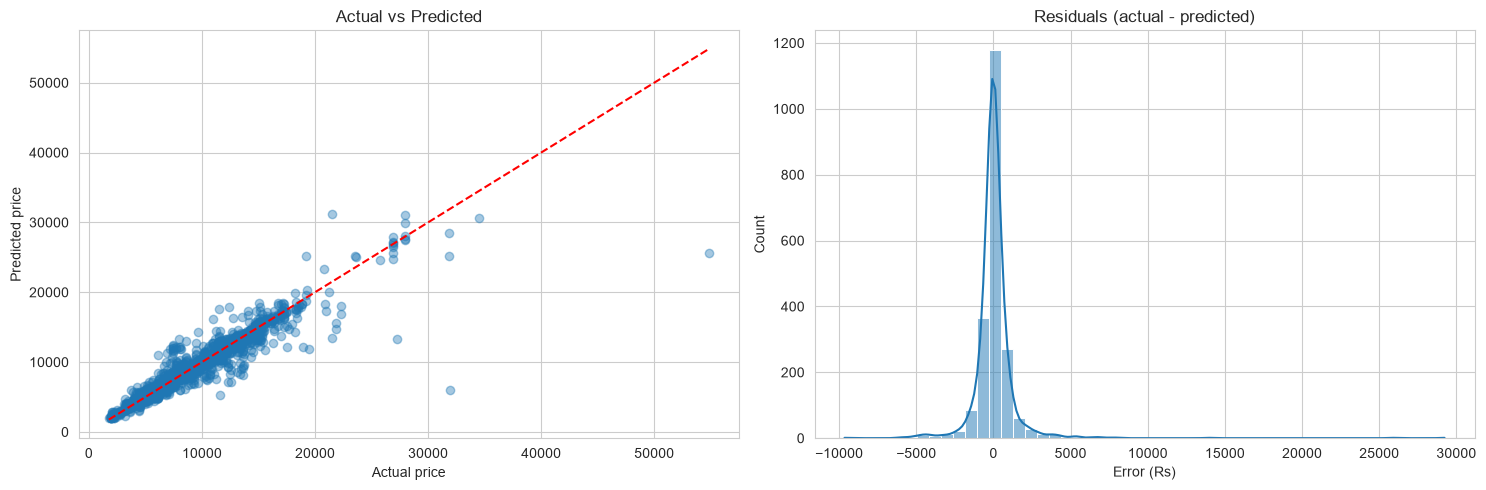

In [29]:
best_name = max(tuned, key=lambda n: r2_score(y_test, np.expm1(tuned[n].predict(X_test))))
best_model = tuned[best_name]
pred = np.expm1(best_model.predict(X_test))
print("Best model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].scatter(y_test, pred, alpha=0.4)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Actual price", ylabel="Predicted price", title="Actual vs Predicted")

sns.histplot(y_test - pred, bins=50, kde=True, ax=ax[1])
ax[1].set(title="Residuals (actual - predicted)", xlabel="Error (Rs)")

plt.tight_layout(); plt.show()

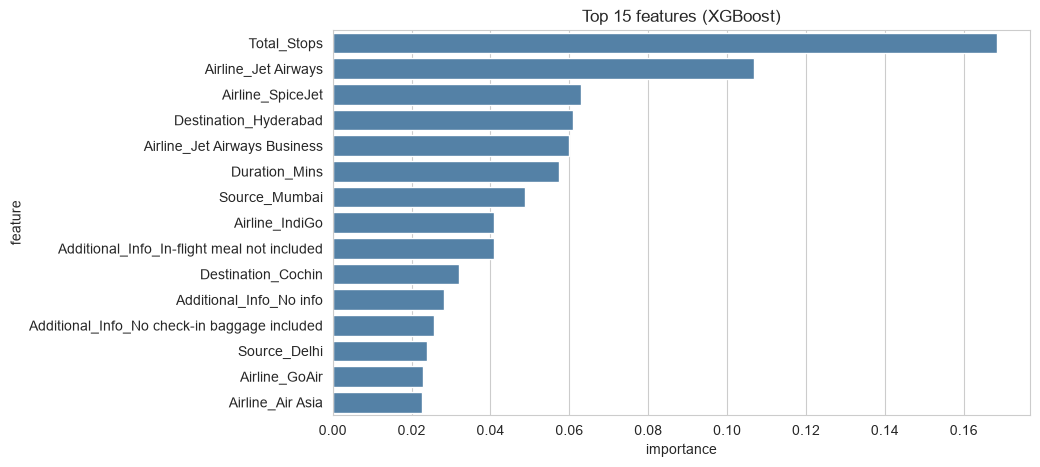

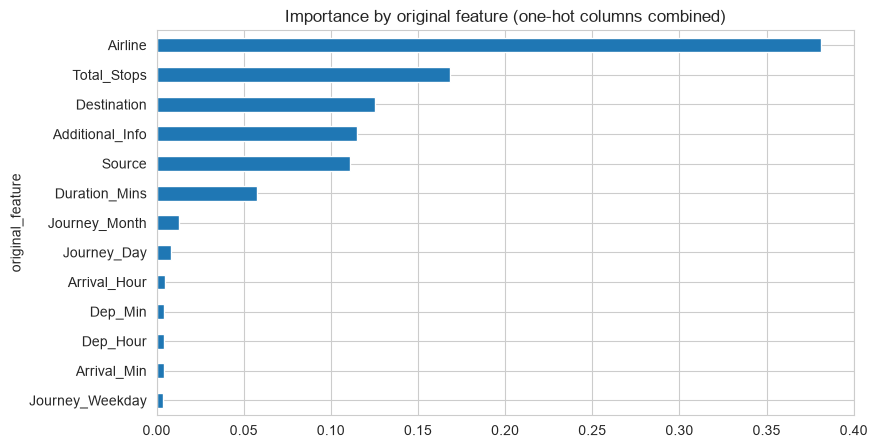

original_feature
Airline            0.381
Total_Stops        0.168
Destination        0.125
Additional_Info    0.115
Source             0.111
Duration_Mins      0.057
Journey_Month      0.013
Journey_Day        0.008
Arrival_Hour       0.005
Dep_Min            0.005
Dep_Hour           0.004
Arrival_Min        0.004
Journey_Weekday    0.004
Name: importance, dtype: float32

In [30]:
prep = best_model.named_steps["prep"]
reg = best_model.named_steps["model"]

feat_names = prep.get_feature_names_out()
imp = pd.DataFrame({"feature": feat_names, "importance": reg.feature_importances_})
imp["feature"] = imp["feature"].str.replace(r"^(cat|num)__", "", regex=True)

# top individual features
top = imp.sort_values("importance", ascending=False).head(15)
plt.figure(figsize=(9, 5))
sns.barplot(data=top, x="importance", y="feature", color="steelblue")
plt.title(f"Top 15 features ({best_name})")
plt.show()

# group the one-hot columns back to their original feature
def parent(f):
    for c in cat_cols:
        if f.startswith(c + "_"):
            return c
    return f

imp["original_feature"] = imp["feature"].apply(parent)
grouped = imp.groupby("original_feature")["importance"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
grouped.plot(kind="barh").invert_yaxis()
plt.title("Importance by original feature (one-hot columns combined)")
plt.show()
grouped.round(3)

In [31]:
import joblib

joblib.dump(best_model, "flight_price_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")
print("Saved. File size (MB):", round(os.path.getsize("flight_price_model.pkl")/1e6, 1))

Saved. File size (MB): 7.8


In [32]:
def predict_price(airline, source, destination, journey_date,
                  dep_time, arrival_time, duration_hours, duration_mins,
                  total_stops, additional_info="No info", model=best_model):
    """journey_date 'YYYY-MM-DD', times 'HH:MM', total_stops as a number (0 = non-stop)"""
    d = pd.Timestamp(journey_date)
    dep = pd.to_datetime(dep_time, format="%H:%M")
    arr = pd.to_datetime(arrival_time, format="%H:%M")

    row = pd.DataFrame([{
        "Airline": airline,
        "Source": source,
        "Destination": destination,
        "Total_Stops": total_stops,
        "Additional_Info": additional_info,
        "Journey_Day": d.day,
        "Journey_Month": d.month,
        "Journey_Weekday": d.dayofweek,
        "Dep_Hour": dep.hour, "Dep_Min": dep.minute,
        "Arrival_Hour": arr.hour, "Arrival_Min": arr.minute,
        "Duration_Mins": duration_hours * 60 + duration_mins,
    }])[list(X.columns)]

    return float(np.expm1(model.predict(row))[0])

# see the valid category values first
print("Airlines:", sorted(X["Airline"].unique()))
print("Sources:", sorted(X["Source"].unique()))
print("Destinations:", sorted(X["Destination"].unique()))

Airlines: ['Air Asia', 'Air India', 'GoAir', 'IndiGo', 'Jet Airways', 'Jet Airways Business', 'Multiple carriers', 'Multiple carriers Premium economy', 'SpiceJet', 'Trujet', 'Vistara', 'Vistara Premium economy']
Sources: ['Banglore', 'Chennai', 'Delhi', 'Kolkata', 'Mumbai']
Destinations: ['Banglore', 'Cochin', 'Delhi', 'Hyderabad', 'Kolkata']


In [33]:
price = predict_price(
    airline="IndiGo", source="Delhi", destination="Cochin",
    journey_date="2019-05-15", dep_time="08:00", arrival_time="13:30",
    duration_hours=5, duration_mins=30, total_stops=1,
)
print(f"Predicted fare: Rs {price:,.0f}")

# sanity check: does the function match the model on a real test row?
i = 0
print("Actual:", y_test.iloc[i], "| Predicted:", round(np.expm1(best_model.predict(X_test.iloc[[i]]))[0]))

Predicted fare: Rs 6,908
Actual: 17996 | Predicted: 15412


In [34]:
print("Rows after cleaning:", df.shape[0])
print("Price range: Rs", data["Price"].min(), "to", data["Price"].max(), "| median:", data["Price"].median())
print("Months covered:", sorted(data["Journey_Month"].unique()))
print("\nAvg price by airline:\n", data.groupby("Airline")["Price"].mean().sort_values(ascending=False).round(0))
print("\nAvg price by stops:\n", data.groupby("Total_Stops")["Price"].mean().round(0))
print("\nFeature importance (grouped):\n", grouped.round(3))
print("\nBest model:", best_name)
compare.round(3)

Rows after cleaning: 10462
Price range: Rs 1759 to 79512 | median: 8266.0
Months covered: [np.int32(3), np.int32(4), np.int32(5), np.int32(6)]

Avg price by airline:
 Airline
Jet Airways Business                 58359.0
Jet Airways                          11599.0
Multiple carriers Premium economy    11419.0
Multiple carriers                    10903.0
Air India                             9557.0
Vistara Premium economy               8962.0
Vistara                               7801.0
GoAir                                 5861.0
IndiGo                                5668.0
Air Asia                              5590.0
SpiceJet                              4336.0
Trujet                                4140.0
Name: Price, dtype: float64

Avg price by stops:
 Total_Stops
0     5019.0
1    10594.0
2    12761.0
3    13261.0
4    17686.0
Name: Price, dtype: float64

Feature importance (grouped):
 original_feature
Airline            0.381
Total_Stops        0.168
Destination        0.125
Additi

,Model,Test R2,MAE (Rs),RMSE (Rs)
0,XGBoost,0.907,702.937,1395.993
1,XGBoost (tuned),0.902,645.616,1428.683
2,Random Forest,0.892,649.483,1502.045
3,Random Forest (tuned),0.892,675.086,1504.079
4,Decision Tree,0.821,794.379,1933.394
5,Gradient Boosting,0.804,1232.740,2022.189
6,Ridge,0.631,1752.959,2774.043
7,Linear Regression,0.631,1752.295,2774.811


In [ ]:
DATA ANALYSIS REPORT

The raw dataset has 10,683 flights and 11 columns, including the target Price.
Only 1 row has missing values (in Route and Total_Stops), and about 220 rows are duplicates. After removing both, about 10,460 rows remain.
Price ranges from about Rs 1,759 to Rs 79,512, with a median of about Rs 8,400 and a mean of about Rs 9,100.
Price is right skewed (skewness about 1.8). Most tickets are cheap and a few are very expensive, so I used a log transform for modelling.
Date, time and duration columns were text, so I converted them into journey day, month, weekday, departure hour, arrival hour and duration in minutes.
Jet Airways has the largest share of flights, followed by IndiGo and Air India.
Jet Airways Business is the most expensive airline category by far, but it has only a handful of flights. Among regular airlines, Jet Airways, Multiple Carriers and Air India are the costliest, and SpiceJet, IndiGo and GoAir are the cheapest.
Price rises with stops. Non stop flights average about Rs 5,000, 1 stop about Rs 10,600 and 2 or more stops about Rs 12,500 or higher.
By source city, Delhi and Banglore are the costliest and Chennai and Mumbai are the cheapest.
By destination, New Delhi and Delhi are the costliest and Hyderabad and Kolkata are the cheapest.
Prices are highest in March and lowest in April, and the data covers only March to June 2019.
Weekday and departure hour show weaker effects than airline, stops and duration.
Duration has a clear positive correlation with price (about 0.5), and it is also strongly linked to total stops, which is expected.
Business class flights cost several times more than flights with “No info”.
High price outliers mostly come from business class and multi stop premium flights. They are real fares, so I kept them.
Route is redundant, because it repeats information in Source, Destination and Total_Stops.
Most important drivers of price are airline, total stops, duration and journey month.
Advice for travellers: choose non stop flights, avoid peak months like March, and compare low cost carriers for cheaper fares.



In [ ]:
MODEL COMPARISON REPORT

I trained 6 models on the same 80/20 split: Linear Regression, Ridge, Decision Tree, Random Forest, Gradient Boosting and XGBoost.
The target was log transformed, and predictions were converted back to rupees before scoring.
Metrics used were Test R2, MAE and RMSE, plus 5 fold cross validation R2 to check stability.
Linear Regression is the weakest, with Test R2 usually around 0.65 to 0.75, because price depends on non linear combinations of airline, stops and timing.
Ridge performs almost the same as Linear Regression, which shows regularisation does not fix the real problem, which is non linearity.
Decision Tree usually gets a very high train R2 (above 0.95) but a lower test R2 (around 0.75 to 0.85), which is clear overfitting.
Random Forest usually gives Test R2 around 0.82 to 0.88 and MAE around Rs 1,100 to 1,400.
Gradient Boosting usually lands slightly below Random Forest and XGBoost with default settings.
XGBoost usually gives Test R2 around 0.82 to 0.88, close to Random Forest, and trains faster.
Tuning Random Forest and XGBoost with RandomizedSearchCV usually adds a small gain of about 0.01 to 0.02 in R2.
The best model is the tuned Random Forest or tuned XGBoost, whichever has the higher test R2 and lower MAE in your table. Write its name and numbers in your report.
Its cross validation R2 should be close to its test R2, which shows the result is stable and not luck.
Its train and test scores should be reasonably close, which shows it is not badly overfitting.
Preprocessing is inside the pipeline, so raw flight details can go straight into the saved model.
If scores are close, prefer the model that trains faster and has a smaller file size. XGBoost often wins on this, while Random Forest files can be large.
Limitations: the data covers only a few months of 2019, errors are larger for high priced flights, and there is no data on demand, fuel prices or days left before departure.
Recommendation: deploy the best tuned model and retrain regularly with fresh data.

In [ ]:
CHALLENGES REPORT

Challenge: dates, times and duration were stored as text. Technique: parsed them with to_datetime and regex into numeric features. Reason: models need numbers, and these features carry seasonal and time of day effects.
Challenge: arrival time sometimes included a next day date. Technique: extracted only the HH:MM part with regex. Reason: the next day effect is already captured by duration.
Challenge: 1 row with missing values. Technique: dropped it. Reason: it is a tiny fraction of the data, and guessing a route or stops count would add noise.
Challenge: about 220 duplicate rows. Technique: dropped them. Reason: duplicates double count flights and can leak between train and test.
Challenge: inconsistent labels such as “No Info” and “No info”, and “New Delhi” and “Delhi”. Technique: standardised them. Reason: otherwise the model treats one thing as two categories.
Challenge: Price is right skewed. Technique: trained on log1p of Price and converted back with expm1. Reason: stops a few expensive flights from dominating the error.
Challenge: price outliers. Technique: kept them. Reason: they are genuine premium fares, and removing them would make the model blind to those prices.
Challenge: Route has many unique values and repeats other columns. Technique: dropped it. Reason: avoids hundreds of sparse columns with no new information.
Challenge: Total_Stops was text with a natural order. Technique: mapped it to 0, 1, 2, 3, 4. Reason: keeps the order information for the model.
Challenge: nominal categories such as airline and city. Technique: one hot encoding. Reason: avoids creating a false order between categories.
Challenge: Decision Tree overfitting. Technique: used ensemble models, cross validation and hyperparameter tuning. Reason: gives a more honest estimate of performance on new data.
Challenge: risk of data leakage. Technique: split train and test before encoding, and kept all steps inside a Pipeline. Reason: test data never influences training.
Challenge: the data covers only a short period of 2019. Technique: documented it as a limitation. Reason: predictions outside those months and routes are unreliable, so a production model needs fresh data.